(dro_portfolio_wass:title)=
# Mean-Risk Portfolio with a Wasserstein Ambiguity Set

## Problem Statement and Parameters

In this example, we delve into the mean-risk portfolio optimization problem discussed in {cite:ps}`Mohajerin_Kuhn2018data`. Here, the yearly returns of $m$ assets in a capital market are encapsulated by a random vector $\tilde{\pmb{z}}\in\mathbb{R}^m$. The investor is tasked with making decisions $\pmb{x}\in\mathbb{R}^m$, where each $x_i$ denotes the percentage of available capital invested in the $i$th asset. The formulation of the portfolio optimization problem is solved as the following distributionally robust model,

```{math}
\begin{aligned}
\min~&\sup\limits_{\mathbb{P}\in\mathcal{F}(\epsilon)}\mathbb{E}_{\mathbb{P}}
\left[
-\tilde{\pmb{z}}^{\top}\pmb{x} + \rho\left(\tau + \frac{1}{\alpha}\max\left\{-\tilde{\pmb{z}}^{\top}\pmb{x} - \tau, 0\right\}\right)
\right] \\
\text{s.t. }&\sum\limits_{i=1}^mx_i = 1 \\
&\pmb{x}\in\mathbb{R}_+^m,
\end{align}
```

where the ambiguity set $\mathcal{F}(\epsilon) = \left\{\mathbb{P}\in\mathcal{P}_0(\mathbb{R}^m)\left|d_W\left(\hat{\mathbb{P}}_n, \mathbb{P}\right) \leq \epsilon\right.\right\}$ is the Wasserstein ball of radius $\epsilon$ centered at the empirical distribution $\hat{\mathbb{P}}_n$, represented by a sample dataset with $n$ records. The objective of the robust model is to minimize the weighted summation of the mean and the conditional value at risk (CVaR) of the portfolio loss $-\tilde{\pmb{z}}^{\top}\pmb{x}$ under the worst-case distribution over the ambiguity set  $\mathcal{F}(\epsilon)$, with the confidence level parameter $\alpha\in (0, 1]$ and risk-aversion parameter $\rho \in \mathbb{R}_+$. We follow the piecewise linear expression proposed by {cite:ps}`Rockafellar_Uryasev2000optimization` to reformulate the objective function as its equivalence

```{math}
\min~\sup\limits_{\mathbb{P}\in\mathcal{F}(\epsilon)}\mathbb{E}_{\mathbb{P}}
\left[
\max\limits_{k\in[K]}\left\{
a_k\tilde{\pmb{z}}^{\top}\pmb{x} + b_k\tau
\right\}
\right],
```

where $K=2$, and coefficients $a_k$ and $b_k$ of the piecewise linear function are given below.

```{math}
\begin{cases}
a_1 = -1, & b_1 = \rho \\
a_2 = -1 - \rho/\alpha, & b_2 = \rho-\rho/\alpha
\end{cases}
```

In the subsequent numerical studies, model parameters are configured according to {cite:ps}`Mohajerin_Kuhn2018data` as follows,

- Number of assets is $m=10$;
- The confidence level is $1 - \alpha = 80\%$;
- The risk-aversion coefficient $\rho=10$.

In [1]:
epsilon = 1e-2                            # radius of the Wasserstein ball
rho = 10                                  # risk-aversion coefficient
alpha = 0.2                               # confidence level

a1, b1 = -1, rho                          # coefficients of the piecewise expression
a2, b2 = -1 - rho/alpha, rho - rho/alpha  # coefficients of the piecewise expression

It is assumed that the random return $\tilde{z}_i$ of each asset is decomposable into a systematic risk factor $\psi \sim N(0, 2\%)$ common to all assets and an idiosyncratic risk factor $\zeta_i\in N(i\times 3\%, i\times 2.5\%)$ specific to asset $i$. The empirical distribution of the random returns $\tilde{\pmb{z}}$ is then represented by a randomly generated sample dataset using the `norm_return()` function defined below.

In [2]:
import numpy as np

def norm_return(n, m):

    i = np.arange(1, m+1)
    psi = 0.02 * np.random.normal(size=(n, 1))
    zeta = 0.03*i + 0.025*i*np.random.normal(size=(n, m))
    zhat = psi + zeta

    return zhat

In the following code segment, we generate a empirical dataset of $n=300$ records for $m=10$ assets. The Wasserstein ball radius $\epsilon$ is specified to be $0.01$.

In [3]:
np.random.seed(10)

n, m = 300, 10
zhat = norm_return(n, m)
epsilon = 1e-2

## Equivalent Deterministic Problem

According to **Corollary 5.1** of {cite:ps}`Mohajerin_Kuhn2018data`, the distributionally robust model above with a one-norm Wasserstein ambiguity set under the unconstrained support $\Xi=\mathbb{R}^m$ is equivalent to the deterministic linear program

```{math}
\begin{aligned}
\min~&\lambda \epsilon + \frac{1}{n}\sum\limits_{i=1}^nc_i \\
\text{s.t. }&\sum\limits_{i=1}^mx_i = 1 \\
&b_k\tau + a_k\hat{\pmb{z}}_j^{\top}\pmb{x} \leq c_j &&\forall j\in[n],~\forall k\in[K] \\
&\|-a_k\pmb{x}\|_{\infty} \leq \lambda \\
&\pmb{x}\in\mathbb{R}_+^m, ~\tau \in\mathbb{R}, ~\lambda \in \mathbb{R}, ~\pmb{c}\in \mathbb{R}^n,
\end{aligned}
```

and the deterministic problem is solved by the code below.

In [4]:
from rsome import ro
import rsome as rso

model = ro.Model()

x = model.dvar(m)
lamb = model.dvar()
tau = model.dvar()
c = model.dvar(n)

model.min(lamb*epsilon + (1/n)*c.sum())
model.st(x.sum() == 1, x >= 0)
model.st(b1*tau + a1*(zhat@x) <= c)
model.st(b2*tau + a2*(zhat@x) <= c)
for i in range(n):
    model.st(rso.norm(- a1*x, 'inf') <= lamb)
    model.st(rso.norm(- a2*x, 'inf') <= lamb)

model.solve()

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.0291s


The objective value of the model is shown as follows.

In [5]:
print(f'Minimum objective: {model.get():.4f}')

Minimum objective: -1.2428


## Implementation via the RSOME `dro` Model

According to {cite:ps}`Chen_Sim_Xiong_2020robust`, the Wasserstein ambiguity set $\mathcal{F}(\epsilon)$ can be rewritten as

```{math}
\mathcal{F}(\epsilon) = \left\{
\mathbb{P}\in\mathcal{P}_0\left(\mathbb{R}^m\times\mathbb{R}\times[n]\right) \left|
\begin{array}{ll}
(\tilde{\pmb{z}}, \tilde{u}, \tilde{s}) \sim \mathbb{P} \\
\mathbb{E}_{\mathbb{P}}[\tilde{u}] \leq \epsilon \\
\mathbb{P}\left[\left.\left\|\tilde{\pmb{z}} - \hat{\pmb{z}}_s\right\|_1\leq \tilde{u}\right|\tilde{s}=s\right] = 1 &\forall s \in [n] \\
\mathbb{P}\left[\tilde{s}=s\right] = \frac{1}{n}
\end{array}
\right.
\right\},
```

where $\hat{\pmb{z}}_s$ is the $s$th record of the empirical distribution. The distributionally robust optimization problem solved in the previous section can be solved as an RSOME `dro` model, as demonstrated by the code below. 

In [6]:
from rsome import dro, E
import rsome as rso

model = dro.Model(n)
x = model.dvar(m)
tau = model.dvar()

z = model.rvar(m)
u = model.rvar()
fset = model.ambiguity()
for s in range(n):
    fset[s].suppset(rso.norm(z - zhat[s], 1) <= u)
fset.exptset(E(u) <= epsilon)
pr = model.p
fset.probset(pr == 1/n)

r = z @ x
model.minsup(E(rso.maxof(a1*r + b1*tau,
                         a2*r + b2*tau)), forall=fset)
model.st(x.sum() == 1, x >= 0)

model.solve()

Being solved by the Scipy LP solver...
Solution status: 0
Running time: 0.5920s


In [7]:
print(f'Minimum objective: {model.get():.4f}')

Minimum objective: -1.2428


## Impact of the Wasserstein Radius

In this section, we will visualize the optimal investment decisions under different values of Wasserstein radius $\epsilon$. The distributionally robust portfolio model is defined as the following function `portfolio_wass()`, where the input arguments are the empirical distribution `zhat` and the selected radius value `epsilon`.

In [8]:
from rsome import dro
from rsome import cpt_solver as cpt
from rsome import E
import rsome as rso

def portfolio_wass(zhat, epsilon):

    n, m = zhat.shape

    model = ro.Model()

    x = model.dvar(m)
    lamb = model.dvar()
    tau = model.dvar()
    s = model.dvar(n)

    model.min(lamb*epsilon + (1/n)*s.sum())
    model.st(x.sum() == 1, x >= 0)
    model.st(b1*tau + a1*(zhat@x)  <= s)
    model.st(b2*tau + a2*(zhat@x)  <= s)
    for i in range(n):
        model.st(rso.norm(- a1*x, 'inf') <= lamb)
        model.st(rso.norm(- a2*x, 'inf') <= lamb)

    model.solve(cpt, display=False)

    return x.get()

Then the function is invoked under different Wasserstein radius values in the following code segment, and the experiments are repeated for `repeats=50` times.

In [9]:
from multiprocess import Pool

n, m = 300, 10
n_jobs = 12
repeats = 50
epsilon_values = 10 ** np.linspace(-3, 0, 12)
sols = np.zeros((repeats, len(epsilon_values), m))
for rep in range(repeats):
    zhat = norm_return(n, m)
    with Pool(n_jobs) as pr:
        params = [[zhat, epsilon] for epsilon in epsilon_values]
        results = pr.starmap(portfolio_wass, params)
    sols[rep] = np.array(results)

Finally, the average portfolio weights are illustrated by the following figure. Please refer to **Fig. 4** of {cite:ps}`Mohajerin_Kuhn2018data` for the same results.

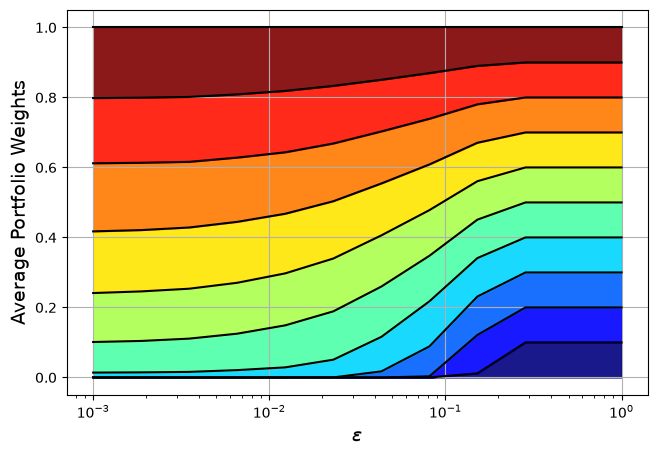

In [10]:
import matplotlib.pyplot as plt
import matplotlib as mpl

plt.figure(figsize=(7.5, 5))

sols_mean = sols.mean(axis=0)
bottom = 0
colors = mpl.colormaps['jet'](np.linspace(0, 1, m))
for i in range(m):
    plt.fill_between(epsilon_values, bottom, bottom+sols_mean[:, i],
                     alpha=0.9, color=colors[i])
    plt.plot(epsilon_values, bottom+sols_mean[:, i],
             linewidth='1.5', color='k')
    bottom += sols_mean[:, i]

plt.xscale('log')
plt.xlabel(r'$\epsilon$', fontsize=14)
plt.ylabel('Average Portfolio Weights', fontsize=14)
plt.grid()
plt.show()

<br>
<br>

<font size="5">Reference</font>

```{bibliography}
:filter: docname in docnames
```